# 30 Day Mapping Challenge

In [71]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path
from rasterio.merge import merge
import numpy as np
from rasterio.windows import from_bounds
from shapely.geometry import box
from rasterio.plot import plotting_extent
from sklearn.neighbors import NearestNeighbors

# Points
### nyc farmers markets colored by how clusteres they are

In [72]:
# NYC Farmers Markets
markets_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "8vwk-6iz2/export.csv?accessType=DOWNLOAD"
)

markets_df = pd.read_csv(markets_url)

# Inspect the columns
print(markets_df.columns.tolist())
print(markets_df.head())

['Year', 'Market Name', 'Borough', 'Street Address', 'Community District', 'Latitude', 'Longitude', 'Days of Operation', 'Hours of Operations', 'Season Dates', 'Accepts EBT', 'Open Year-Round', 'Stellar Cooking Demonstrations']
   Year                      Market Name    Borough  \
0  2025         175th Street Greenmarket  Manhattan   
1  2025  4th Ave Sunset Park Greenmarket   Brooklyn   
2  2025          57th Street Greenmarket  Manhattan   
3  2025          79th Street Greenmarket  Manhattan   
4  2025  7th Ave Sunset Park Greenmarket   Brooklyn   

                                Street Address  Community District   Latitude  \
0  W. 175th St. bet. Wadsworth Ave. & Broadway               112.0  40.845948   
1                            4th Ave. 60th St.               307.0  40.647975   
2                         57th St. & 10th Ave.               104.0  40.769117   
3                     79th St. & Columbus Ave.               107.0  40.782295   
4                          7th Ave. 

In [73]:
# NYC Borough Boundaries
boroughs_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "gthc-hcne/query.geojson?accessType=DOWNLOAD"
)

boroughs = gpd.read_file(boroughs_url)

print(boroughs.head())
print(boroughs.crs)

                  :id           :version                      :created_at  \
0  row-7tjt.uvyw.7ibt  rv-4t64_6m9c_35an 2026-05-26 19:35:49.449000+00:00   
1  row-j4kv.jskm_sgt9  rv-86hu-khv5~6gub 2026-05-26 19:35:49.449000+00:00   
2  row-fmcn_egr2.4ed7  rv-fzx7_87v2_ghcm 2026-05-26 19:35:49.449000+00:00   
3  row-sgcq-gqfx_iqid  rv-n78r-xzdj~m3tb 2026-05-26 19:35:49.449000+00:00   
4  row-xiai_c2ui_hanx  rv-4ed5_kbz3-4cqg 2026-05-26 19:35:49.449000+00:00   

                       :updated_at borocode       boroname     shape_area  \
0 2026-05-26 19:35:49.449000+00:00        5  Staten Island  1623618358.46   
1 2026-05-26 19:35:49.449000+00:00        3       Brooklyn  1934462607.75   
2 2026-05-26 19:35:49.449000+00:00        4         Queens  3041419716.32   
3 2026-05-26 19:35:49.449000+00:00        1      Manhattan  636631537.285   
4 2026-05-26 19:35:49.449000+00:00        2          Bronx  1187199168.58   

      shape_leng                                           geometry  
0  3

In [74]:

# Convert coordinates and year to numeric
markets_df["Latitude"] = pd.to_numeric(
    markets_df["Latitude"], errors="coerce"
)

markets_df["Longitude"] = pd.to_numeric(
    markets_df["Longitude"], errors="coerce"
)

markets_df["Year"] = pd.to_numeric(
    markets_df["Year"], errors="coerce"
)

# Remove rows with missing coordinates
markets_df = markets_df.dropna(
    subset=["Latitude", "Longitude"]
).copy()

# Keep the most recent year available
latest_year = int(markets_df["Year"].max())

markets_latest = markets_df[
    markets_df["Year"] == latest_year
].copy()

# Remove duplicate market locations
markets_latest = markets_latest.drop_duplicates(
    subset=["Latitude", "Longitude"]
).copy()

print("Year selected:", latest_year)
print("Number of market locations:", len(markets_latest))


Year selected: 2026
Number of market locations: 103


In [75]:
markets = gpd.GeoDataFrame(
    markets_latest,
    geometry=gpd.points_from_xy(
        markets_latest["Longitude"],
        markets_latest["Latitude"]
    ),
    crs="EPSG:4326"
)

markets.head()

,Year,Market Name,Borough,Street Address,Community District,Latitude,Longitude,Days of Operation,Hours of Operations,Season Dates,Accepts EBT,Open Year-Round,Stellar Cooking Demonstrations,geometry
2115,2026,170 Farm Stand,Bronx,1406 Townsend Ave.,204.0,40.840138,-73.916591,Wednesday,2 p.m. - 6 p.m.,NaN,No,No,No,POINT (-73.91659 40.84014)
2116,2026,Bissel Gardens Farmers Market,Bronx,Baychester Ave across from Camp St.,212.0,40.900941,-73.846740,Saturday,8 a.m.- 4 p.m.,NaN,Yes,No,No,POINT (-73.84674 40.90094)
2117,2026,Bronx Borough Hall Greenmarket,Bronx,161st St. & Grand Concourse,204.0,40.827335,-73.922911,Tuesday,8 a.m. - 4 p.m.,NaN,Yes,No,No,POINT (-73.92291 40.82734)
2118,2026,Bronx Park East (BxPE) Farmers Market,Bronx,"2045 Bronx Park East, Bronx Park (Bradley Play...",211.0,40.851713,-73.867786,Sunday,9 a.m. - 4 p.m.,NaN,Yes,No,No,POINT (-73.86779 40.85171)
2119,2026,BronxWorks Farm Stand,Bronx,1130 Grand Concourse,204.0,40.832759,-73.919296,Thursday,10 a.m.-2 p.m.,NaN,Yes,No,No,POINT (-73.9193 40.83276)


In [76]:
# Project both layers into NYC's projected coordinate system
markets_proj = markets.to_crs(epsg=2263)
boroughs_proj = boroughs.to_crs(epsg=2263)

# Extract point coordinates in projected units (US survey feet)
coords = np.column_stack([
    markets_proj.geometry.x,
    markets_proj.geometry.y
])

# Find the two nearest points:
# 1. The market itself
# 2. Its nearest other market
nn = NearestNeighbors(n_neighbors=2)
nn.fit(coords)

distances, indices = nn.kneighbors(coords)

# The first distance is 0 because it is the market itself.
# The second distance is to the nearest other market.
markets_proj["nearest_market_m"] = distances[:, 1] * 0.3048006096

# Optional: distance to the three nearest OTHER markets
nn3 = NearestNeighbors(n_neighbors=4)
nn3.fit(coords)

distances_3, indices_3 = nn3.kneighbors(coords)

markets_proj["mean_3_nearest_m"] = (
    distances_3[:, 1:4].mean(axis=1) * 0.3048006096
)

markets_proj[
    ["Market Name", "nearest_market_m", "mean_3_nearest_m"]
].head()

,Market Name,nearest_market_m,mean_3_nearest_m
2115,170 Farm Stand,614.270846,710.874937
2116,Bissel Gardens Farmers Market,3663.633854,3870.255630
2117,Bronx Borough Hall Greenmarket,675.120940,805.703310
2118,Bronx Park East (BxPE) Farmers Market,1856.713701,1991.988244
2119,BronxWorks Farm Stand,675.120940,919.314948


findfont: Failed to find font weight ultralight, now using 400.


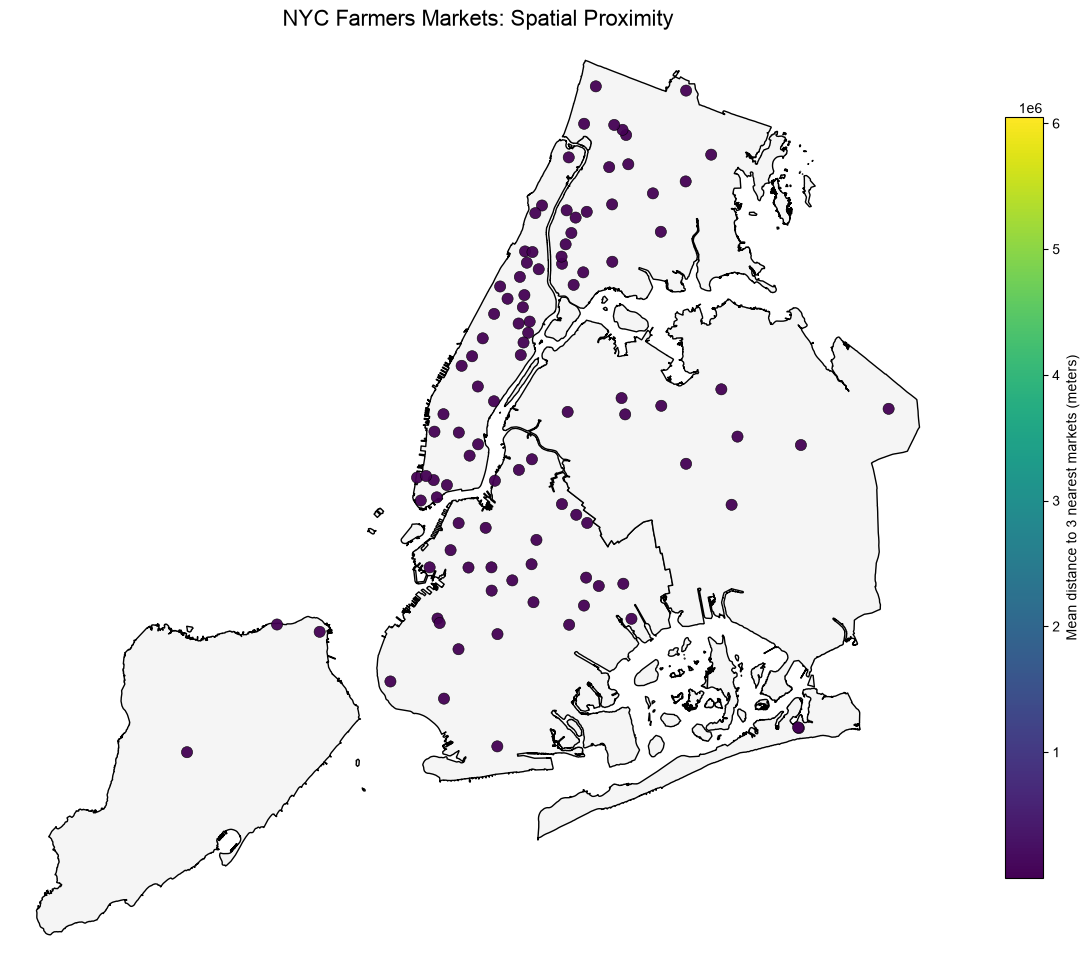

In [77]:

fig, ax = plt.subplots(figsize=(12, 12))

# Borough boundaries underneath the points
boroughs_proj.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=1
)

# Farmers markets colored by proximity
markets_proj.plot(
    ax=ax,
    column="mean_3_nearest_m",
    cmap="viridis",
    markersize=65,
    alpha=0.95,
    edgecolor="black",
    linewidth=0.4,
    legend=True,
    legend_kwds={
        "label": "Mean distance to 3 nearest markets (meters)",
        "shrink": 0.65
    }
)

# Zoom to the borough boundaries, with a small margin
xmin, ymin, xmax, ymax = boroughs_proj.total_bounds

x_margin = (xmax - xmin) * 0.03
y_margin = (ymax - ymin) * 0.03

ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)

ax.set_title(
    "NYC Farmers Markets: Spatial Proximity",
    fontsize=16
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [78]:
# Load Recognized Shop Healthy Stores
stores_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "ud4g-9x9z/export.csv?accessType=DOWNLOAD"
)

stores_df = pd.read_csv(stores_url)

# Inspect the data
print(stores_df.columns.tolist())
print(stores_df.head())


['Store Name', 'Street Address', 'Borough', 'Zip \nCode', 'Year Awarded', 'Program \nWave', 'Latitude', 'Longitude', 'Community Board', 'Council District', 'BIN', 'BBL', 'Census Tract (2020)', 'Neighborhood Tabulation Area (NTA) (2020)']
                 Store Name           Street Address Borough  Zip \nCode  \
0        Rivas Deli Grocery    651 East 183rd Street   Bronx       10458   
1                    C-Town  1761 Southern Boulevard   Bronx       10460   
2      La India Mini Market      1942 Marmion Avenue   Bronx       10460   
3              Los Hermanos         2019 Vyse Avenue   Bronx       10460   
4  Price Choice Food Market    820 East 180th Street   Bronx       10460   

   Year Awarded  Program \nWave   Latitude  Longitude  Community Board  \
0          2013               1  40.852568 -73.887484            206.0   
1          2013               1  40.837267 -73.888016            203.0   
2          2013               1  40.842942 -73.887136            206.0   
3        

In [79]:

# Convert coordinates to numeric values
stores_df["Latitude"] = pd.to_numeric(
    stores_df["Latitude"], errors="coerce"
)

stores_df["Longitude"] = pd.to_numeric(
    stores_df["Longitude"], errors="coerce"
)

# Remove records without coordinates
stores_df = stores_df.dropna(
    subset=["Latitude", "Longitude"]
).copy()

# Convert to a GeoDataFrame
stores = gpd.GeoDataFrame(
    stores_df,
    geometry=gpd.points_from_xy(
        stores_df["Longitude"],
        stores_df["Latitude"]
    ),
    crs="EPSG:4326"
)

# Project to the same coordinate system as your existing map
stores_proj = stores.to_crs(epsg=2263)

print("Number of Shop Healthy stores:", len(stores_proj))


Number of Shop Healthy stores: 669


findfont: Failed to find font weight ultralight, now using 400.


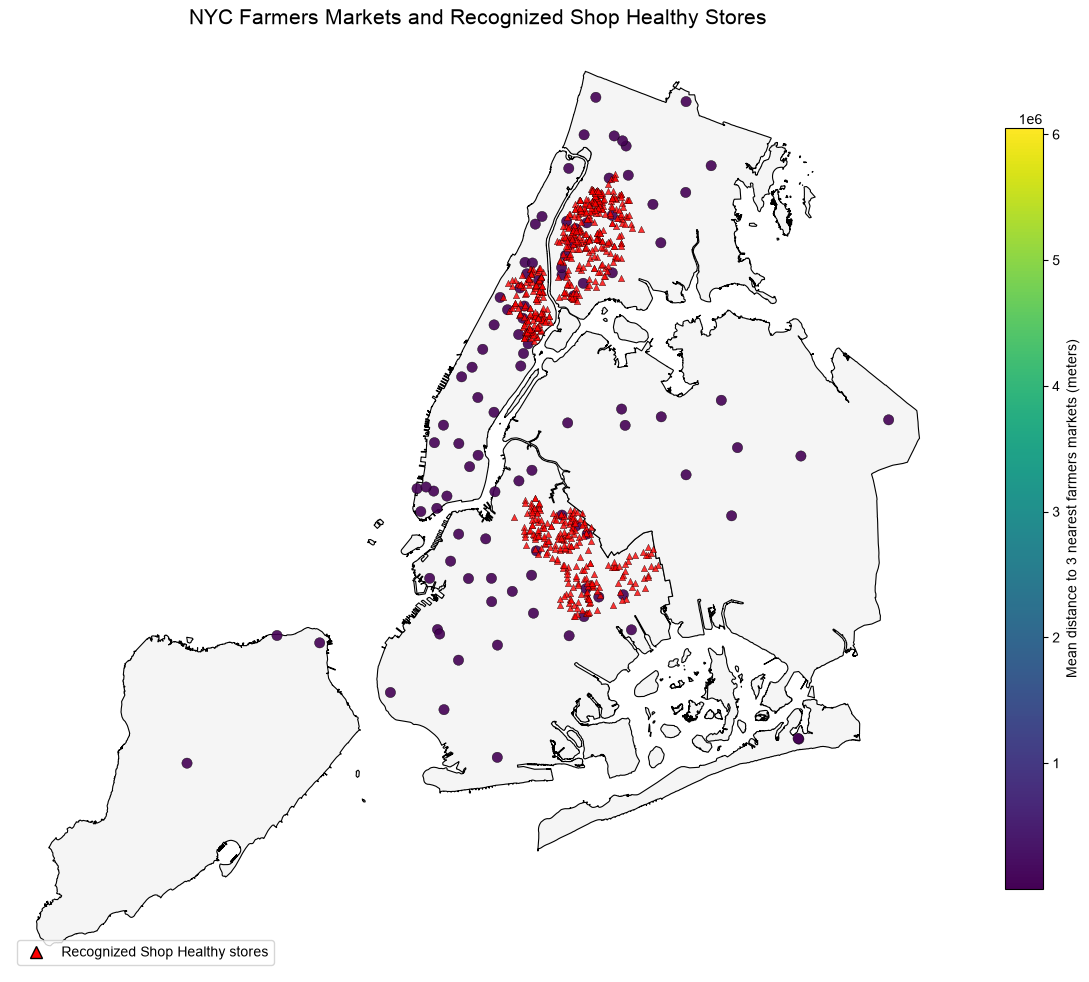

In [80]:

fig, ax = plt.subplots(figsize=(12, 12))

# 1. Borough boundaries
boroughs_proj.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8,
    zorder=1
)

# 2. Farmers markets: colored by proximity
markets_proj.plot(
    ax=ax,
    column="mean_3_nearest_m",
    cmap="viridis",
    markersize=55,
    edgecolor="black",
    linewidth=0.3,
    alpha=0.9,
    legend=True,
    legend_kwds={
        "label": "Mean distance to 3 nearest farmers markets (meters)",
        "shrink": 0.65
    },
    zorder=2
)

# 3. Recognized Shop Healthy stores: red triangles
stores_proj.plot(
    ax=ax,
    color="red",
    marker="^",
    markersize=22,
    edgecolor="black",
    linewidth=0.3,
    alpha=0.8,
    zorder=3
)

# Zoom to NYC borough boundaries
xmin, ymin, xmax, ymax = boroughs_proj.total_bounds

x_margin = (xmax - xmin) * 0.03
y_margin = (ymax - ymin) * 0.03

ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)

# Title and legend
ax.set_title(
    "NYC Farmers Markets and Recognized Shop Healthy Stores",
    fontsize=15,
    pad=15
)

from matplotlib.lines import Line2D

legend_items = [
    Line2D(
        [0], [0],
        marker="^",
        color="w",
        markerfacecolor="red",
        markeredgecolor="black",
        markersize=8,
        label="Recognized Shop Healthy stores"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower left",
    frameon=True
)

ax.set_axis_off()
plt.tight_layout()
plt.show()


In [81]:
# Reproject your existing GeoDataFrames to Web Mercator
# This assumes boroughs, markets, and stores already exist.

boroughs_web = boroughs.to_crs(epsg=3857)
markets_web = markets.to_crs(epsg=3857)
stores_web = stores.to_crs(epsg=3857)

print("Boroughs:", len(boroughs_web))
print("Farmers markets:", len(markets_web))
print("Shop Healthy stores:", len(stores_web))
print("Borough columns:", boroughs_web.columns.tolist())

Boroughs: 5
Farmers markets: 103
Shop Healthy stores: 669
Borough columns: [':id', ':version', ':created_at', ':updated_at', 'borocode', 'boroname', 'shape_area', 'shape_leng', 'geometry']


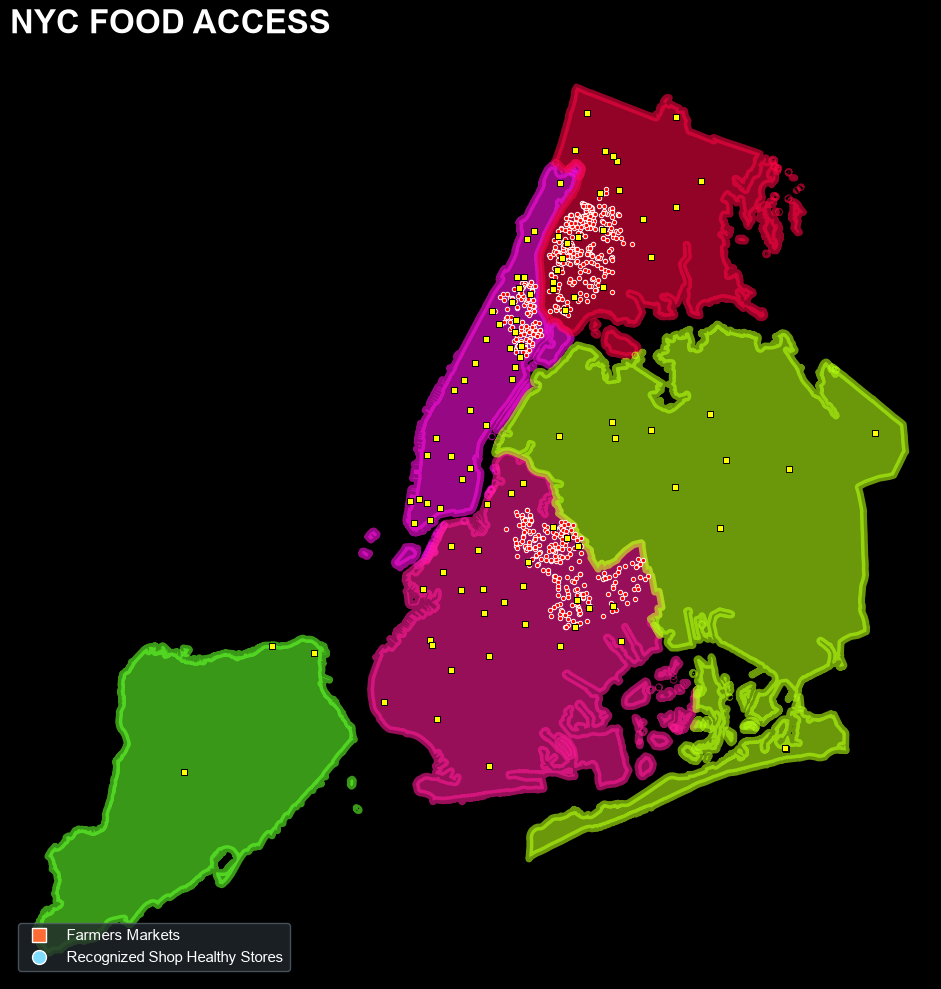

In [82]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Borough colors
borough_colors = {
    "Manhattan": "#fb0fde",
    "Bronx": "#f60642",
    "Brooklyn": "#fd1a95",
    "Queens": "#b4fe11",
    "Staten Island": "#61fe29"
}

borough_col = "boroname"

# Create map
fig, ax = plt.subplots(figsize=(10, 10))
fig.patch.set_facecolor("#000000")
ax.set_facecolor("#000000")

# Draw boroughs as the basemap
for borough, color in borough_colors.items():
    subset = boroughs_web[boroughs_web[borough_col] == borough]

    if not subset.empty:
        subset.plot(
            ax=ax,
            facecolor=color,
            edgecolor=color,
            alpha=0.6,
            linewidth=5,
            zorder=1
        )

# Farmers markets
markets_web.plot(
    ax=ax,
    color="yellow",
    markersize=20,
    marker="s",
    edgecolor="black",
    linewidth=0.7,
    zorder=6
)

# Recognized Shop Healthy stores
stores_web.plot(
    ax=ax,
    color="red",
    markersize=10,
    marker="o",
    edgecolor="white",
    linewidth=0.7,
    zorder=5
)

# Title
ax.set_title(
    "NYC FOOD ACCESS",
    fontsize=24,
    fontweight="bold",
    color="white",
    pad=20,
    loc="left"
)

# Legend
legend_items = [
    Line2D(
        [0], [0], marker="s", linestyle="None",
        markerfacecolor="#FF6B35", markeredgecolor="white",
        markersize=10, label="Farmers Markets"
    ),
    Line2D(
        [0], [0], marker="o", linestyle="None",
        markerfacecolor="#7FDBFF", markeredgecolor="white",
        markersize=10, label="Recognized Shop Healthy Stores"
    )
]

legend = ax.legend(
    handles=legend_items,
    loc="lower left",
    facecolor="#20272D",
    edgecolor="#56616B",
    fontsize=11
)

for text in legend.get_texts():
    text.set_color("white")

# Map extent
xmin, ymin, xmax, ymax = boroughs_web.total_bounds
xpad = (xmax - xmin) * 0.03
ypad = (ymax - ymin) * 0.03

ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)
ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()
plt.show()

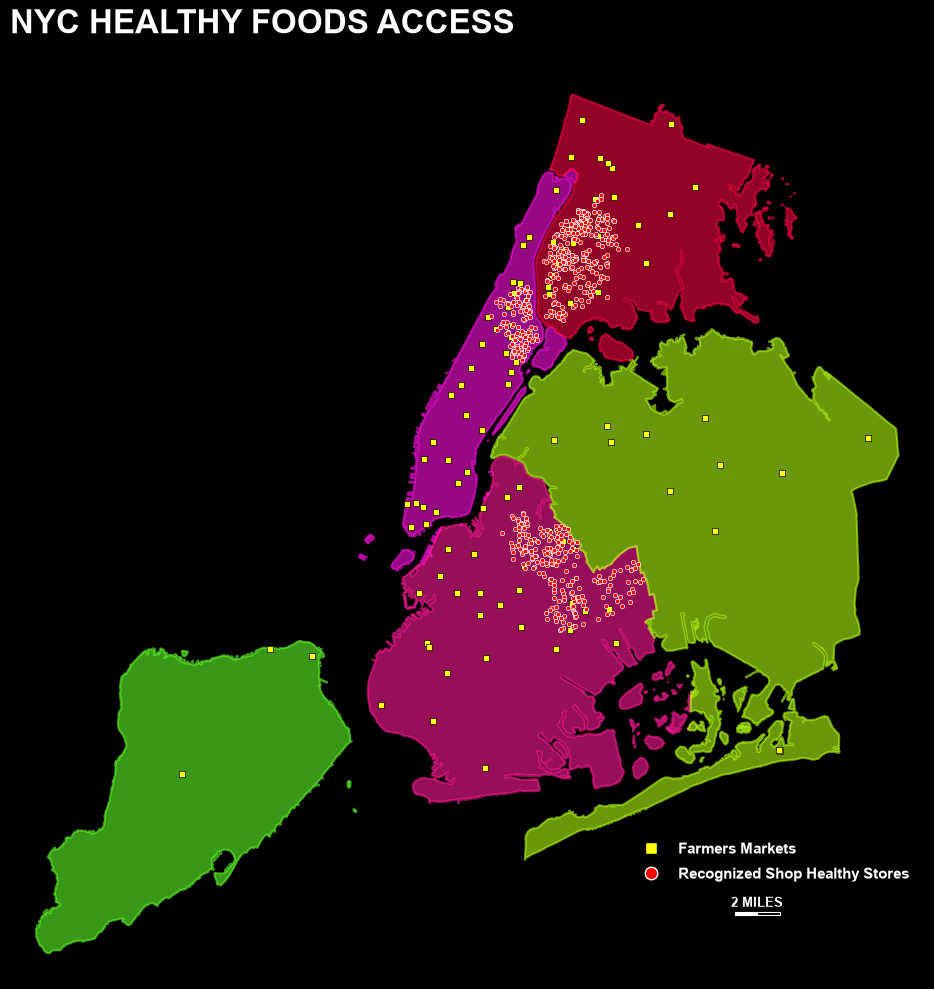

In [86]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

borough_colors = {
    "Manhattan": "#fb0fde",
    "Bronx": "#f60642",
    "Brooklyn": "#fd1a95",
    "Queens": "#b4fe11",
    "Staten Island": "#61fe29"
}

fig, ax = plt.subplots(figsize=(10, 10), facecolor="black")
ax.set_facecolor("black")

# Draw boroughs
for borough, color in borough_colors.items():
    subset = boroughs_web[boroughs_web["boroname"] == borough]
    if not subset.empty:
        subset.plot(
            ax=ax,
            facecolor=color,
            edgecolor=color,
            alpha=0.6,
            linewidth=1.5,
            zorder=1
        )

# Plot data points
markets_web.plot(
    ax=ax, color="yellow", markersize=20, marker="s",
    edgecolor="black", linewidth=0.5, zorder=5
)

stores_web.plot(
    ax=ax, color="red", markersize=10, marker="o",
    edgecolor="white", linewidth=0.5, zorder=6
)

# Title
ax.set_title(
    "NYC HEALTHY FOODS ACCESS",
    fontsize=24,
    fontweight="bold",
    color="white",
    pad=15,
    loc="left"
)

# Extent
xmin, ymin, xmax, ymax = boroughs_web.total_bounds
xpad = (xmax - xmin) * 0.03
ypad = (ymax - ymin) * 0.03
ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)

# Larger, transparent legend in the bottom-right
legend_items = [
    Line2D(
        [0], [0], marker="s", linestyle="None",
        markerfacecolor="yellow", markeredgecolor="black",
        markersize=9, label="Farmers Markets"
    ),
    Line2D(
        [0], [0], marker="o", linestyle="None",
        markerfacecolor="red", markeredgecolor="white",
        markersize=9, label="Recognized Shop Healthy Stores"
    )
]

legend = ax.legend(
    handles=legend_items,
    loc="lower right",
    bbox_to_anchor=(0.99, 0.10),
    frameon=False,
    fontsize=11,
    handletextpad=0.8,
    labelspacing=0.7,
    borderaxespad=0
)

for text in legend.get_texts():
    text.set_color("white")
    text.set_fontweight("bold")

# ---- Scale bar directly below the legend ----
# Approximate 2-mile scale bar in EPSG:3857
scale_meters = 2 * 1609.344

xmin, ymin, xmax, ymax = boroughs_web.total_bounds
xpad = (xmax - xmin) * 0.03
ypad = (ymax - ymin) * 0.03
x_range = xmax - xmin
y_range = ymax - ymin

bar_x = xmax - xpad - x_range * 0.16
bar_y = ymin + ypad + y_range * 0.015
bar_height = y_range * 0.003
half_bar = scale_meters / 2

# Black-and-white scale bar
ax.add_patch(Rectangle(
    (bar_x, bar_y),
    half_bar, bar_height,
    facecolor="white",
    edgecolor="white",
    linewidth=0.8,
    zorder=10
))

ax.add_patch(Rectangle(
    (bar_x + half_bar, bar_y),
    half_bar, bar_height,
    facecolor="black",
    edgecolor="white",
    linewidth=0.8,
    zorder=10
))

ax.text(
    bar_x + scale_meters / 2,
    bar_y + bar_height * 2,
    "2 MILES",
    ha="center",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    color="white",
    zorder=10
)

# Final formatting
ax.set_aspect("equal")
ax.set_axis_off()
fig.tight_layout()
plt.show()

# Lines
## elevation contours or eathquake lines

# Polygons
## Idea: Recreation areas of mount hood layered over slope dem

In [12]:
#contour lines
contour_path = "data/ELEV_The_Dalles_W_OR_1X1_Shape/Shape/Elev_Contour.shp"

contours = gpd.read_file(contour_path)

print("CRS:", contours.crs)
print("Number of features:", len(contours))
print("Geometry types:")
print(contours.geom_type.value_counts())
print(contours.columns.tolist())
print(contours.head())

CRS: EPSG:4269
Number of features: 23599
Geometry types:
LineString         20316
MultiLineString     3283
Name: count, dtype: int64
['permanent_', 'source_fea', 'source_dat', 'source_d_1', 'source_ori', 'loaddate', 'fcode', 'contourele', 'contouruni', 'contourint', 'nedresolut', 'cell_id', 'Shape_Leng', 'ObjectID', 'geometry']
                             permanent_ source_fea  \
0  6647a789-832a-4489-a8a3-f9554eecaf77       None   
1  a8156bf6-4fe4-4cd6-9c7e-7c06da80c015       None   
2  694fedcc-7d2b-4ce9-85f3-993fed234917       None   
3  a0f0433c-f70d-4ec9-b37d-ae49ac0aefaa       None   
4  8db9bade-08ea-4601-ae93-f11679610ad0       None   

                             source_dat  \
0  f785dbc0-1e7e-4566-a973-78204772c4ef   
1  f785dbc0-1e7e-4566-a973-78204772c4ef   
2  f785dbc0-1e7e-4566-a973-78204772c4ef   
3  f785dbc0-1e7e-4566-a973-78204772c4ef   
4  f785dbc0-1e7e-4566-a973-78204772c4ef   

                                          source_d_1            source_ori  \
0  Conto

In [13]:
#elevation dem

dem_folder = Path("data/dem")

dem_files = list(dem_folder.glob("*.tif"))

for file in dem_files:
    print(file.name)

USGS_13_n46w122_20121001.tif
USGS_13_n46w122_20260202.tif
USGS_13_n46w122_20211129.tif


In [14]:
dem_path = "data/dem/USGS_13_n46w122_20260202.tif"

with rasterio.open(dem_path) as src:
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Dimensions:", src.width, "x", src.height)
    print("Resolution:", src.res)

CRS: EPSG:4269
Bounds: BoundingBox(left=-122.00055555599357, bottom=44.999444443906896, right=-120.99944444380549, top=46.00055555609498)
Dimensions: 10812 x 10812
Resolution: (9.259259269220167e-05, 9.259259269220167e-05)


Saved cropped DEM to: outputs/mount_hood_dem_clipped.tif
Crop dimensions: (1890, 2700)


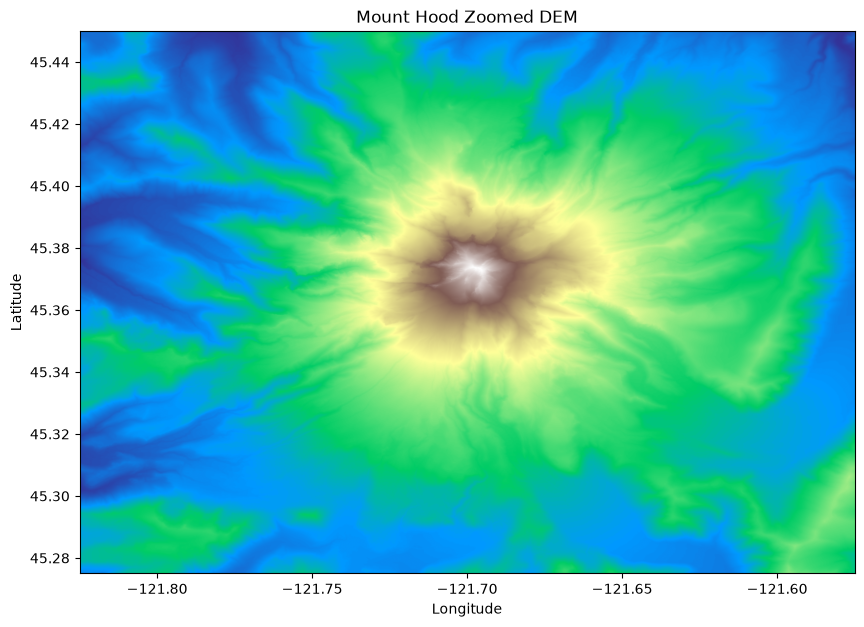

In [15]:
dem_path = Path("data/dem/USGS_13_n46w122_20260202.tif")
output_path = Path("outputs/mount_hood_dem_clipped.tif")

west = -121.825
south = 45.275
east = -121.575
north = 45.45

with rasterio.open(dem_path) as src:
    window = from_bounds(
        west, south, east, north,
        transform=src.transform
    )

    dem = src.read(1, window=window, masked=True)
    transform = src.window_transform(window)

    profile = src.profile.copy()
    profile.update(
        height=dem.shape[0],
        width=dem.shape[1],
        transform=transform
    )

    output_path.parent.mkdir(parents=True, exist_ok=True)

    nodata = src.nodata if src.nodata is not None else -9999.0
    profile.update(nodata=nodata)

    with rasterio.open(output_path, "w", **profile) as dst:
        dst.write(dem.filled(nodata), 1)

print(f"Saved cropped DEM to: {output_path}")
print(f"Crop dimensions: {dem.shape}")

# Preview the crop
plt.figure(figsize=(10, 10))
plt.imshow(
    dem,
    extent=[west, east, south, north],
    origin="upper",
    cmap="terrain"
)
plt.title("Mount Hood Zoomed DEM")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

In [16]:
gdb_path = Path("data/Winter Recreation Sites, Mt. Hood and Willamette National Forests, Oregon, (polygon)/data/v93/climatevulnerabilityfinal_data0.gdb")

recreation = gpd.read_file(
    gdb_path,
    layer="WinterRecSites_Polys"
)

print("Number of recreation areas:", len(recreation))
print("CRS:", recreation.crs)
print(recreation[["RECAREANAME", "FORESTNAME", "TYPE"]].head())



Number of recreation areas: 7
CRS: PROJCS["NAD_1983_Oregon_Washington_Albers",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",34],PARAMETER["longitude_of_center",-120],PARAMETER["standard_parallel_1",43],PARAMETER["standard_parallel_2",48],PARAMETER["false_easting",600000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]
        RECAREANAME                FORESTNAME             TYPE
0       COOPER SPUR  Mt. Hood National Forest  SKI AREA ALPINE
1  MT. HOOD MEADOWS  Mt. Hood National Forest  SKI AREA ALPINE
2           SKIBOWL  Mt. Hood National Forest  SKI AREA ALPINE
3            SUMMIT  Mt. Hood National Forest  SKI AREA ALPINE
4  TIMBERLINE LODGE  Mt. Hood National Forest  SKI AREA ALPINE


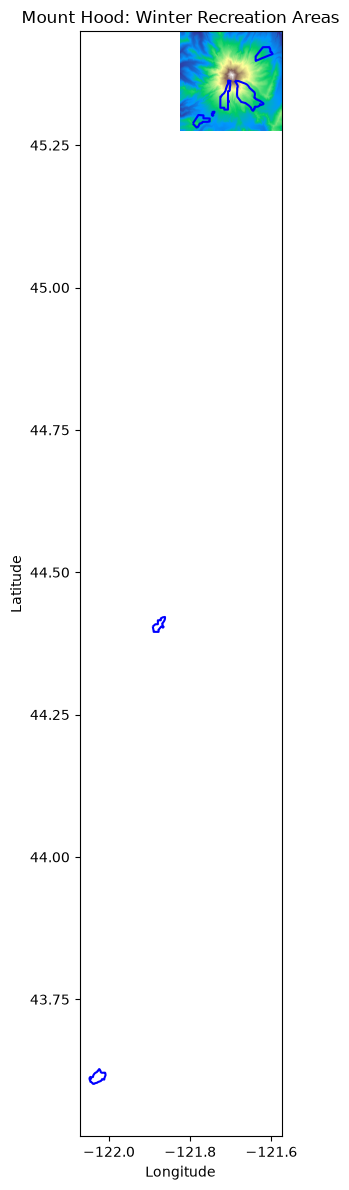

In [17]:
dem_path = "outputs/mount_hood_dem_clipped.tif"

with rasterio.open(dem_path) as src:
    dem = src.read(1, masked=True)
    bounds = src.bounds
    dem_crs = src.crs

recreation_plot = recreation.to_crs(dem_crs)

fig, ax = plt.subplots(figsize=(12, 12))

ax.imshow(
    dem,
    extent=[
        bounds.left,
        bounds.right,
        bounds.bottom,
        bounds.top
    ],
    origin="upper",
    cmap="terrain"
)

recreation_plot.boundary.plot(
    ax=ax,
    edgecolor="blue",
    linewidth=1.5
)

ax.set_title("Mount Hood: Winter Recreation Areas")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()
plt.show()

In [26]:
with rasterio.open(dem_path) as src:
    dem_crs = src.crs
    bounds = src.bounds

dem_boundary = box(
    bounds.left,
    bounds.bottom,
    bounds.right,
    bounds.top
)

recreation_check = recreation.to_crs(dem_crs).copy()

recreation_check["dem_status"] = recreation_check.geometry.apply(
    lambda geom: (
        "Outside DEM" if not geom.intersects(dem_boundary)
        else "Fully inside DEM" if dem_boundary.covers(geom)
        else "Partially outside DEM"
    )
)

print(recreation_check["dem_status"].value_counts())

dem_status
Fully inside DEM    5
Outside DEM         2
Name: count, dtype: int64


In [27]:
# Keep only polygons fully within the DEM boundaries
recreation_clipped = recreation_check[
    recreation_check["dem_status"] == "Fully inside DEM"
].copy()

print("Original polygon count:", len(recreation_check))
print("Remaining polygon count:", len(recreation_clipped))
print("Removed polygon count:", len(recreation_check) - len(recreation_clipped))

Original polygon count: 7
Remaining polygon count: 5
Removed polygon count: 2


In [28]:
dem_path = "outputs/mount_hood_dem_clipped.tif"

# Read the DEM
with rasterio.open(dem_path) as src:
    dem = src.read(1, masked=True)
    dem_crs = src.crs
    extent = plotting_extent(src)

recreation_map = recreation_clipped.to_crs(dem_crs)

print("DEM CRS:", dem_crs)
print("Recreation polygons:", len(recreation_map))

DEM CRS: EPSG:4269
Recreation polygons: 5


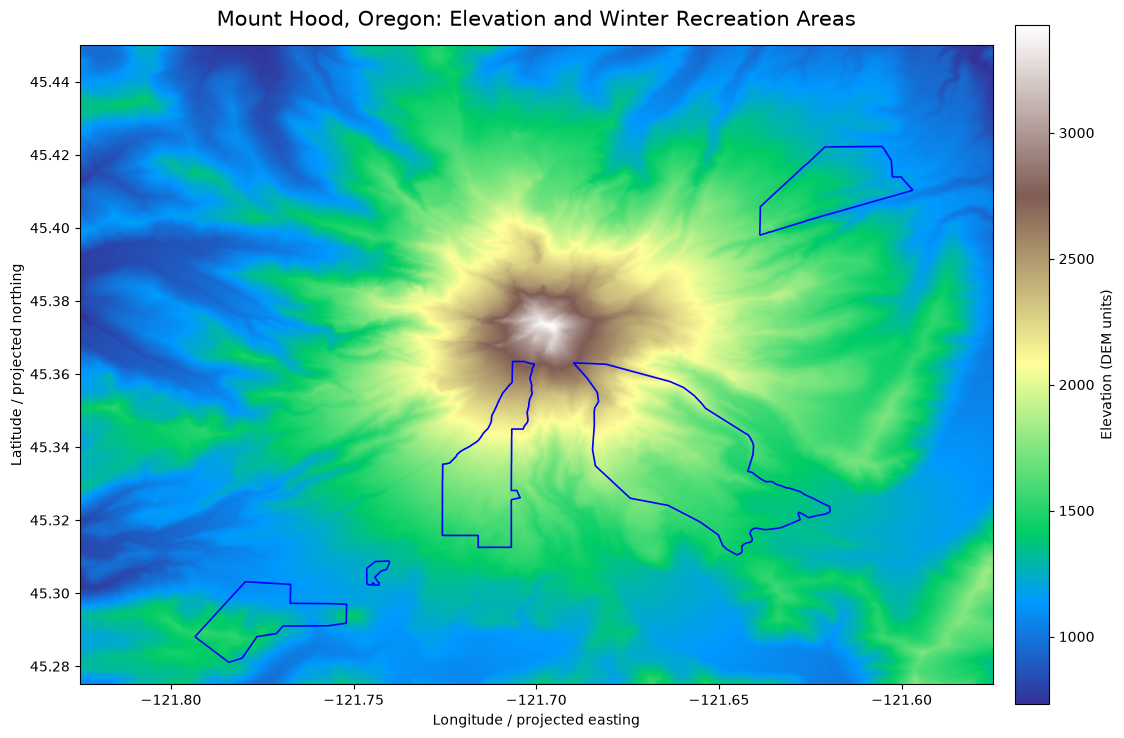

In [29]:
fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    dem,
    extent=extent,
    origin="upper",
    cmap="terrain"
)

recreation_map.boundary.plot(
    ax=ax,
    color="blue",
    linewidth=1.2
)

cbar = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.02)
cbar.set_label("Elevation (DEM units)")

ax.set_title("Mount Hood, Oregon: Elevation and Winter Recreation Areas",
             fontsize=15, pad=14)
ax.set_xlabel("Longitude / projected easting")
ax.set_ylabel("Latitude / projected northing")
ax.set_aspect("equal")

plt.tight_layout()
plt.show()

### mapping styles

In [30]:

with rasterio.open(dem_path) as src:
    dem_crs = src.crs
    dem_boundary = gpd.GeoDataFrame(
        geometry=[box(*src.bounds)],
        crs=dem_crs
    )

contours_map = contours.to_crs(dem_crs)

contours_clipped = gpd.clip(
    contours_map,
    dem_boundary
)

print("Original contours:", len(contours_map))
print("Clipped contours:", len(contours_clipped))

Original contours: 23599
Clipped contours: 1726


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


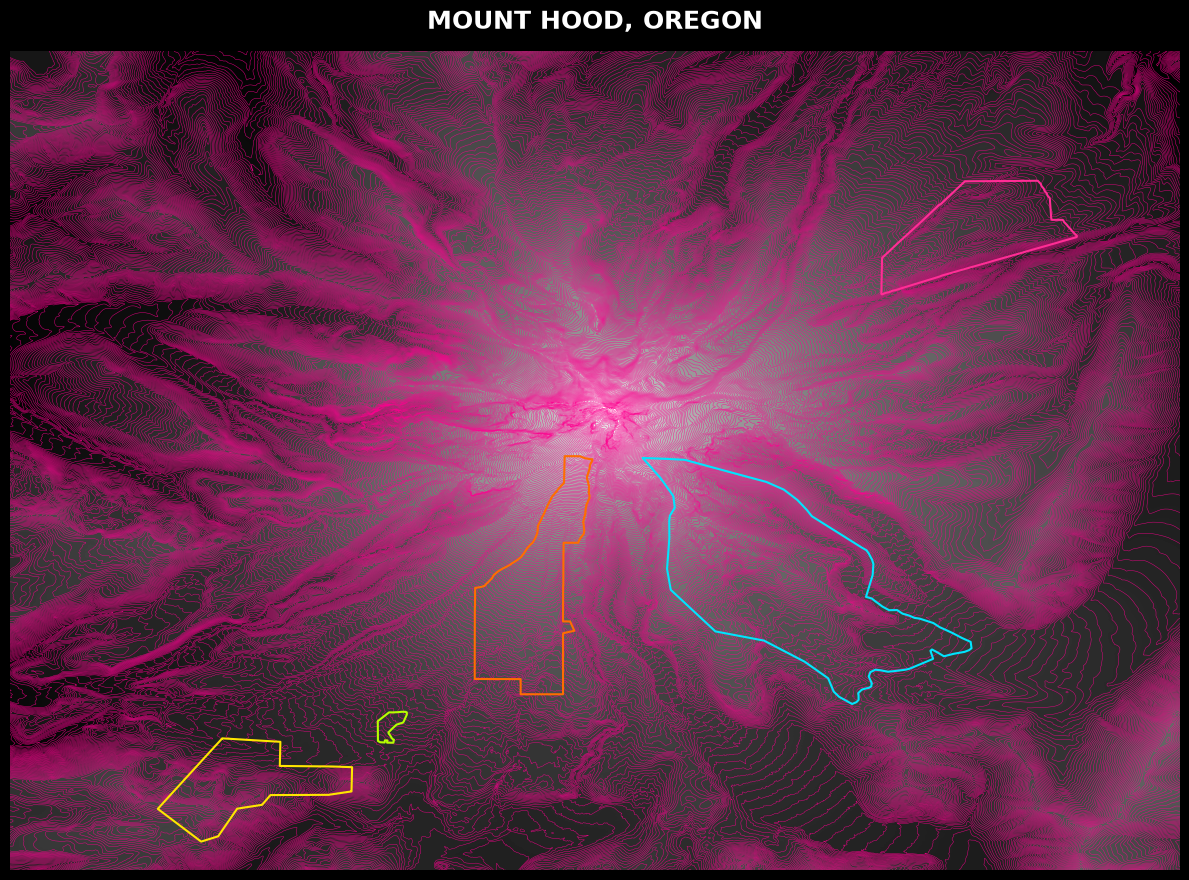

In [53]:
import matplotlib.pyplot as plt
import rasterio
from rasterio.plot import plotting_extent
from pathlib import Path

# Read the clipped DEM
with rasterio.open(dem_path) as src:
    dem = src.read(1, masked=True)
    extent = plotting_extent(src)
    dem_crs = src.crs

# Match all vector layers to the DEM CRS
recreation_map = recreation_clipped.to_crs(dem_crs)
contours_clipped = contours_clipped.to_crs(dem_crs)

# Bright outline colors, cycling through the polygons
bright_colors = [
    "#FF2D95",  # hot pink
    "#00E5FF",  # electric cyan
    "#FFE600",  # bright yellow
    "#B6FF00",  # lime
    "#FF6D00",  # vivid orange
    "#D500F9",  # purple
]

fig, ax = plt.subplots(figsize=(12, 12), facecolor="black")
ax.set_facecolor("black")

# 1. Grayscale elevation background
ax.imshow(
    dem,
    extent=extent,
    origin="upper",
    cmap="grey",  # or "gist_earth", "topo"
    interpolation="nearest",
    zorder=1
)

# 2. White contour lines
contours_clipped.plot(
    ax=ax,
    color="#FF0090",
    linewidth=0.35,
    alpha=0.85,
    zorder=2
)

# 3. Transparent recreation polygons with bright outlines
for i, (_, polygon) in enumerate(recreation_map.iterrows()):
    color = bright_colors[i % len(bright_colors)]

    gpd.GeoSeries(
        [polygon.geometry],
        crs=recreation_map.crs
    ).plot(
        ax=ax,
        facecolor="none",
        edgecolor=color,
        linewidth=1.5,
        zorder=3
    )

# Styling
ax.set_title(
    "MOUNT HOOD, OREGON",
    color="white",
    fontsize=18,
    fontweight="bold",
    pad=16
)

ax.set_axis_off()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

In [54]:
import geopandas as gpd

# Make sure both layers use the same CRS
contours_map = contours_clipped.to_crs(recreation_clipped.crs)

# Keep only the geometry of the recreation areas for clipping
recreation_areas = recreation_clipped[["geometry"]].copy()

# Clip contour lines to recreation-area boundaries
contours_in_recreation = gpd.clip(
    contours_map,
    recreation_areas
)

print("Contour segments inside recreation areas:", len(contours_in_recreation))

Contour segments inside recreation areas: 270


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:168: RuntimeWarning: invalid value encountered in intersection
  return lib.intersection(a, b, **kwargs)


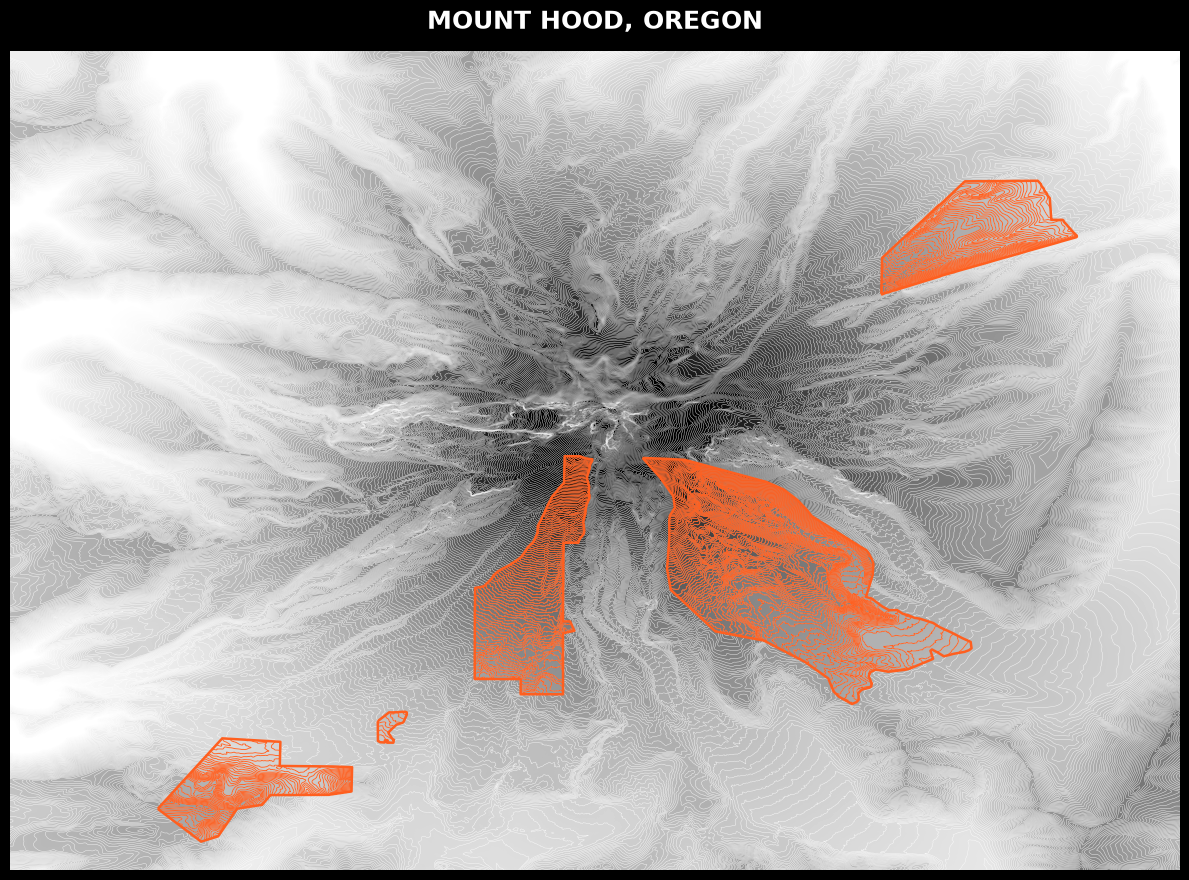

In [61]:
import matplotlib.pyplot as plt
import numpy as np
import rasterio
from rasterio.plot import plotting_extent

# Read the DEM
with rasterio.open(dem_path) as src:
    dem = src.read(1, masked=True)
    extent = plotting_extent(src)

# Calculate strong contrast limits
valid_elevation = dem.compressed()
vmin, vmax = np.percentile(valid_elevation, [2, 98])

# Set up figure
fig, ax = plt.subplots(figsize=(12, 12), facecolor="black")
ax.set_facecolor("black")

# 1. Plot high-contrast grayscale DEM
ax.imshow(
    dem,
    extent=extent,
    origin="upper",
    cmap="grey_r",
    vmin=vmin,
    vmax=vmax,
    interpolation="nearest",
    zorder=1
)

# 2. Plot all contours in white first
contours_map.plot(
    ax=ax,
    color="white",
    linewidth=0.35,
    alpha=0.8,
    zorder=2
)

# 3. Overlay colored contour segments inside recreation areas
bright_colors = [
    "#FF5F1F",  # Pink
    "#FF5F1F",  # Cyan
    "#FF5F1F",  # Yellow
    "#FF5F1F",  # Lime
    "#FF5F1F",  # Orange
    "#FF5F1F",  # Purple
]

# Draw bright boundary outlines around recreation areas
for i, (_, area) in enumerate(recreation_clipped.iterrows()):
    gpd.GeoSeries(
        [area.geometry],
        crs=recreation_clipped.crs
    ).boundary.plot(
        ax=ax,
        color=bright_colors[i % len(bright_colors)],
        linewidth=1.8,
        zorder=4
    )

for i, (_, area) in enumerate(recreation_clipped.iterrows()):
    # Select contour segments that intersect this recreation area
    area_contours = gpd.clip(
        contours_map,
        gpd.GeoDataFrame(
            geometry=[area.geometry],
            crs=recreation_clipped.crs
        )
    )

    if not area_contours.empty:
        area_contours.plot(
            ax=ax,
            color=bright_colors[i % len(bright_colors)],
            linewidth=0.65,
            alpha=1,
            zorder=3
        )

# 4. Final styling
ax.set_title(
    "MOUNT HOOD, OREGON",
    color="white",
    fontsize=18,
    fontweight="bold",
    pad=16
)

ax.set_axis_off()
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

# Clusters